In [11]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
from torchvision.transforms import v2

In [33]:
# Download training data from open datasets.
training_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

# Download test data from open datasets.
test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

100.0%
100.0%
100.0%
100.0%


In [59]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [58]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

class NeuralNetwork(nn.Module):
   
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
        
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits
    
model = NeuralNetwork().to(device)
print(model)

Using cpu device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [60]:
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=.1)



In [ ]:
def train(loss, optimizer, model, dataloader):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X,y = X.to(device), y.to(device)
        
        #forward
        pred = model(X)
        loss_fn = loss(pred, y)
        
        #backward
        loss_fn.backward()
        optimizer.step()
        optimizer.zero_grad()
    
        

In [62]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [63]:
epoch = 5

for t in range(epoch):
    print(f"Epoch {t + 1} \n --------------------------------")
    train(loss, optimizer, model, train_dataloader)
    test(test_dataloader, model, loss)
    

Epoch 1 
 --------------------------------
Test Error: 
 Accuracy: 93.6%, Avg loss: 0.211608 

Epoch 2 
 --------------------------------
Test Error: 
 Accuracy: 95.7%, Avg loss: 0.138330 

Epoch 3 
 --------------------------------
Test Error: 
 Accuracy: 96.9%, Avg loss: 0.104863 

Epoch 4 
 --------------------------------
Test Error: 
 Accuracy: 97.3%, Avg loss: 0.088328 

Epoch 5 
 --------------------------------
Test Error: 
 Accuracy: 97.5%, Avg loss: 0.079202 



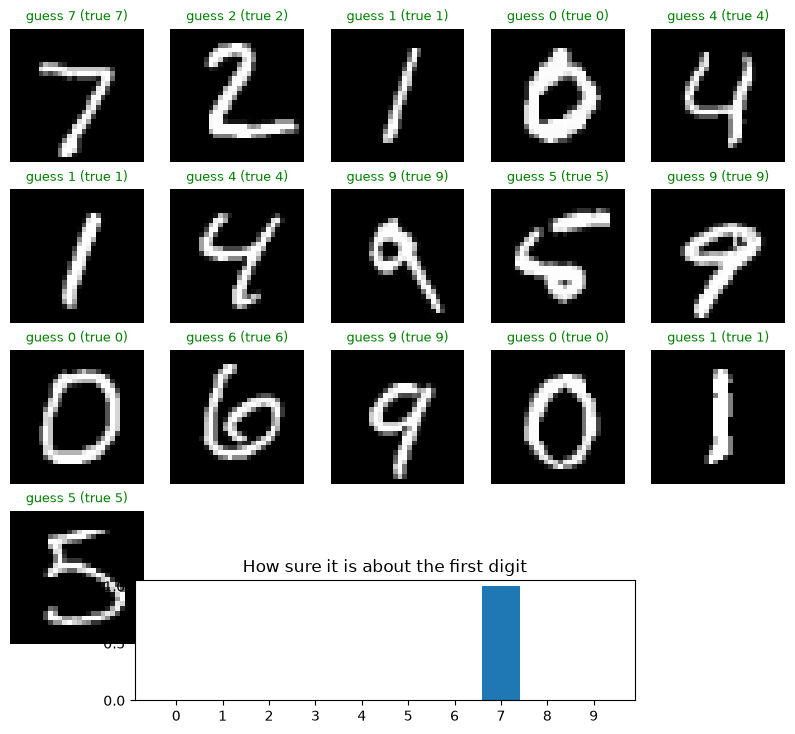

In [65]:
import matplotlib.pyplot as plt

model.eval()
X, y = next(iter(test_dataloader))
X, y = X.to(device), y.to(device)
with torch.no_grad():
    probs = model(X).softmax(dim=1)
preds = probs.argmax(1)

fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for i, ax in enumerate(axes.flat[:16]):
    ax.imshow(X[i].squeeze().cpu(), cmap="gray")
    ok = preds[i] == y[i]
    ax.set_title(f"guess {preds[i].item()} (true {y[i].item()})",
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")

for ax in axes.flat[16:]:
    ax.axis("off")
bar_ax = fig.add_axes([0.25, 0.04, 0.5, 0.15])
bar_ax.bar(range(10), probs[0].cpu())
bar_ax.set_xticks(range(10))
bar_ax.set_title("How sure it is about the first digit")
plt.show()